In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


In [6]:
import pandas as pd

url = "https://huggingface.co/datasets/Datasetssickness/CarData/resolve/main/car%20data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())
print(df.shape)
print(df.columns)

Dataset loaded successfully!
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
(301, 9)
Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='object')


In [8]:
print(df.columns)

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='object')


In [9]:
categorical_features = [
    'Fuel_Type',
    'Seller_Type',
    'Transmission'
]

numerical_features = [
    'Present_Price',
    'Kms_Driven',
    'Owner',
    'Car_Age'
]

In [10]:
# Check duplicate values
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove missing values
df.dropna(inplace=True)

print("\nDataset after cleaning:")
print(df.shape)

Duplicate rows: 2

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Dataset after cleaning:
(299, 9)


In [11]:
df['Car_Age'] = 2026 - df['Year']

print(df[['Year', 'Car_Age']].head())

   Year  Car_Age
0  2014       12
1  2013       13
2  2017        9
3  2011       15
4  2014       12


In [12]:
print(df.describe())

              Year  Selling_Price  Present_Price     Kms_Driven       Owner  \
count   299.000000     299.000000     299.000000     299.000000  299.000000   
mean   2013.615385       4.589632       7.541037   36916.752508    0.043478   
std       2.896868       4.984240       8.567887   39015.170352    0.248720   
min    2003.000000       0.100000       0.320000     500.000000    0.000000   
25%    2012.000000       0.850000       1.200000   15000.000000    0.000000   
50%    2014.000000       3.510000       6.100000   32000.000000    0.000000   
75%    2016.000000       6.000000       9.840000   48883.500000    0.000000   
max    2018.000000      35.000000      92.600000  500000.000000    3.000000   

          Car_Age  
count  299.000000  
mean    12.384615  
std      2.896868  
min      8.000000  
25%     10.000000  
50%     12.000000  
75%     14.000000  
max     23.000000  


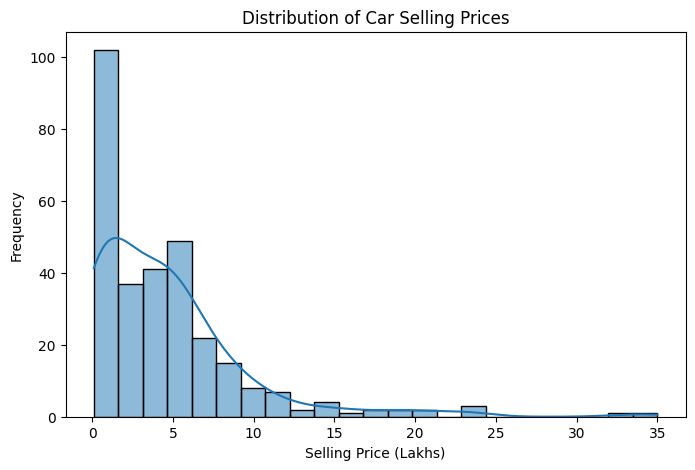

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['Selling_Price'], kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

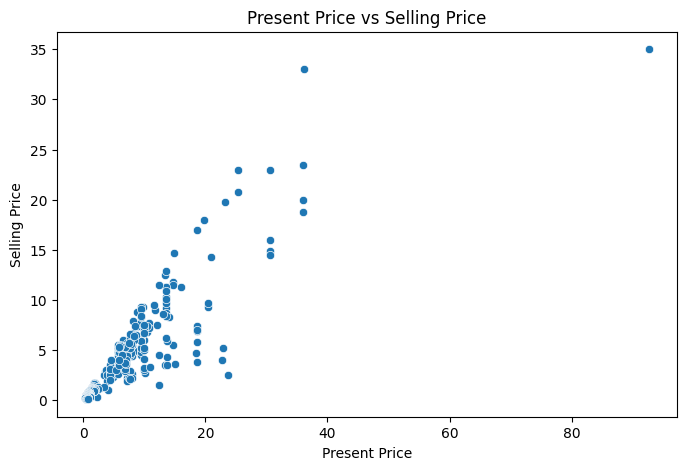

In [14]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df['Present_Price'],
    y=df['Selling_Price']
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")

plt.show()

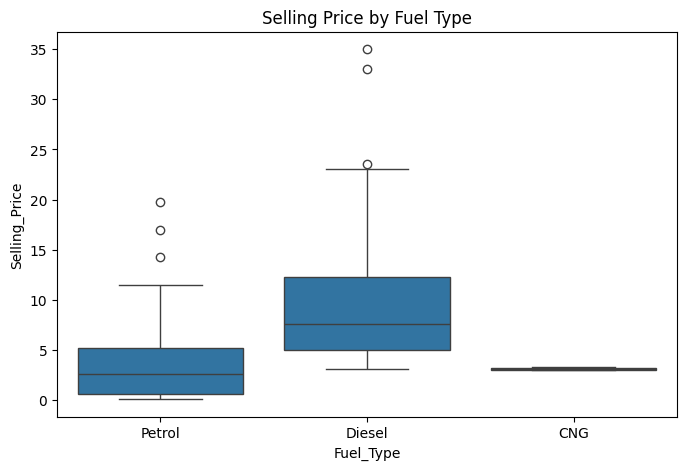

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Fuel_Type',
    y='Selling_Price',
    data=df
)

plt.title("Selling Price by Fuel Type")
plt.show()

In [16]:
X = df.drop(
    ['Selling_Price', 'Car_Name', 'Year'],
    axis=1
)

y = df['Selling_Price']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner  \
0           5.59       27000    Petrol      Dealer       Manual      0   
1           9.54       43000    Diesel      Dealer       Manual      0   
2           9.85        6900    Petrol      Dealer       Manual      0   
3           4.15        5200    Petrol      Dealer       Manual      0   
4           6.87       42450    Diesel      Dealer       Manual      0   

   Car_Age  
0       12  
1       13  
2        9  
3       15  
4       12  

Target:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (239, 7)
Testing data: (60, 7)


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

print("Preprocessing completed!")

Preprocessing completed!


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

print("Model created successfully!")

Model created successfully!


In [20]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [21]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head())

print("\nPredicted Prices:")
print(y_pred[:5])

Actual Prices:
283    8.99
267    8.35
166    0.45
9      7.45
78     5.25
Name: Selling_Price, dtype: float64

Predicted Prices:
[ 9.5023   8.194    0.43215  6.91175 18.6532 ]


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 1.5615683333333332
Mean Squared Error: 14.424072451500008
Root Mean Squared Error: 3.7979036917094158
R2 Score: 0.4403474295518832


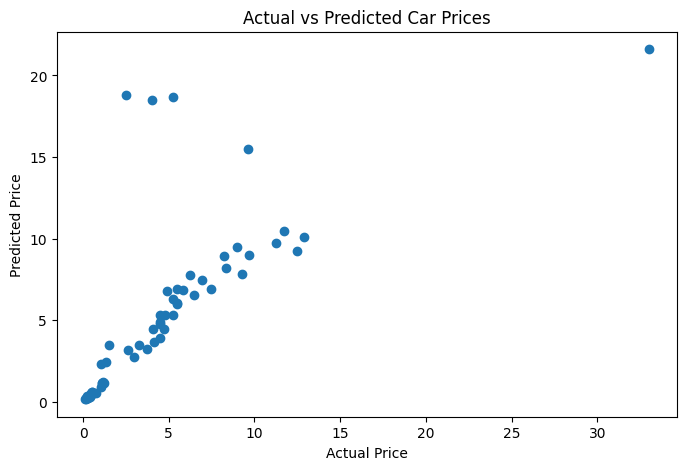

In [23]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

                        Feature    Importance
7      remainder__Present_Price  8.998321e-01
10           remainder__Car_Age  7.388120e-02
8         remainder__Kms_Driven  1.361319e-02
6      cat__Transmission_Manual  4.143715e-03
5   cat__Transmission_Automatic  3.470942e-03
4   cat__Seller_Type_Individual  1.598389e-03
3       cat__Seller_Type_Dealer  1.479893e-03
1         cat__Fuel_Type_Diesel  1.023912e-03
2         cat__Fuel_Type_Petrol  9.516900e-04
9              remainder__Owner  3.950518e-06
0            cat__Fuel_Type_CNG  9.999704e-07


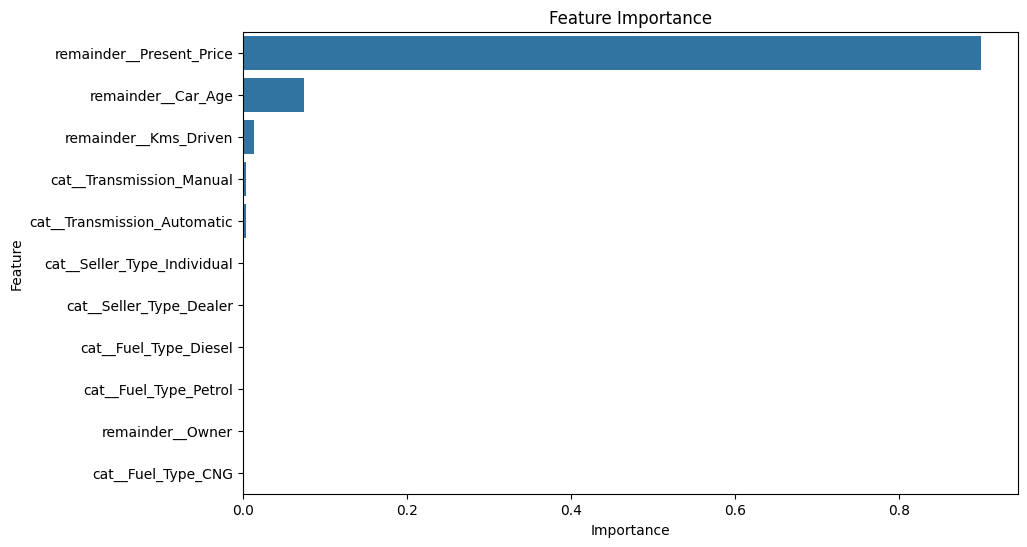

In [24]:
feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

importances = model.named_steps[
    'regressor'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df
)

plt.title("Feature Importance")
plt.show()

In [25]:
new_car = pd.DataFrame({
    'Present_Price': [8.5],
    'Kms_Driven': [30000],
    'Fuel_Type': ['Petrol'],
    'Seller_Type': ['Dealer'],
    'Transmission': ['Manual'],
    'Owner': [0],
    'Car_Age': [5]
})

predicted_price = model.predict(new_car)

print(
    "Predicted Car Price:",
    round(predicted_price[0], 2),
    "Lakhs"
)

Predicted Car Price: 6.88 Lakhs
